# EfficientNetV2-S fine-tuning

A different CNN family for the ensemble. `tf_efficientnetv2_s.in21k_ft_in1k` is pretrained on ImageNet only (21k classes, then fine-tuned on 1k) and has 20M parameters, against 88M for ConvNeXt-base. Its blocks (MBConv with squeeze-and-excitation, BatchNorm) differ from ConvNeXt's, so its mistakes should overlap less with Exp1's.

We follow the Exp1 protocol: fold 0 of the saved folds, 384-pixel letterbox, BCEWithLogitsLoss, fixed 0.25 threshold, checkpoint chosen by fold-0 macro F1, horizontal-flip augmentation only. Three things differ because the architecture does:

1. **Its own head warm-up.** Exp0's head fits ConvNeXt's 1024 features, not these 1280. Phase 1 trains a new linear head on the frozen backbone, then phase 2 fine-tunes everything.
2. **Higher learning rates.** Backbone `1e-4` and head `1e-3`, against `1e-5` and `1e-4` for ConvNeXt. EfficientNets usually need larger steps. These are starting guesses, not tuned values.
3. **Frozen BatchNorm statistics.** With a physical batch of 8, batch statistics are noisy. We keep the pretrained running mean and variance fixed; BatchNorm scale and shift still train.

In [1]:
from __future__ import annotations

import importlib
import json
import os
import platform
import random
import re
import subprocess
import sys
import time
from pathlib import Path

import numpy as np
import torch

RUN_TRAINING = True
SMOKE_TEST = False
PROFILE_ONLY = False
BACKUP_TO_DRIVE = os.environ.get('STAGE2_BACKUP_TO_DRIVE', '0') == '1'
DRIVE_FOLDER_NAME = os.environ.get('STAGE2_DRIVE_FOLDER_NAME', 'AI301-stage2')
DRIVE_ROOT = (Path('/content/drive/MyDrive') / DRIVE_FOLDER_NAME).resolve()
ALLOW_WEIGHT_DOWNLOAD = os.environ.get('STAGE2_ALLOW_WEIGHT_DOWNLOAD', '0') == '1'
USE_WANDB = os.environ.get('STAGE2_USE_WANDB', '1') == '1'
REMOVE_RUNTIME_ENV_AFTER_LOAD = os.environ.get('STAGE2_REMOVE_RUNTIME_ENV_AFTER_LOAD', '0') == '1'
WANDB_MODE = 'online'
WANDB_PROJECT = 'ai301-stage2'
BUILD_GRADCAM = True  # Only runs after a completed training run.
BUILD_TEST_PREDICTIONS = True  # Saves test probabilities for ensembling.
BUILD_SUBMISSION = False  # Writes a binary CSV into submissions/ from the saved test probabilities (see the submission cell).
SUBMIT_TO_KAGGLE = False  # No submission API call exists in this notebook.

if not ALLOW_WEIGHT_DOWNLOAD:
    os.environ['HF_HUB_OFFLINE'] = '1'  # Must be set before anything imports huggingface_hub.

MODEL_NAME = 'tf_efficientnetv2_s.in21k_ft_in1k'
RUN_ID = os.environ.get('STAGE2_RUN_ID', 'efficientnetv2s_fold0_seed42')
SEED = 42
VALIDATION_FOLD = 0
THRESHOLD = 0.25
IMAGE_SIZE = 384
BATCH_SIZE = 8  # Not measured on a T4 yet; lower it to 4 if the smoke run runs out of memory.
EFFECTIVE_BATCH_SIZE = 16
HEAD_ONLY_LR = 1e-3
HEAD_EPOCHS = 8  # A 3-epoch smoke-run curve was still climbing (macro F1 0.45, 0.65, 0.77).
HEAD_PATIENCE = 3
MAX_EPOCHS = 8
PATIENCE = 3
MAX_RUN_HOURS = 3.0
BACKBONE_LR = 1e-4
HEAD_LR = 1e-3
WEIGHT_DECAY = 1e-2
NUM_WORKERS = 2 if torch.cuda.is_available() else 0
PRECISION = '32-true'

if EFFECTIVE_BATCH_SIZE % BATCH_SIZE:
    raise ValueError('Effective batch size must be divisible by physical batch size.')
if PROFILE_ONLY and (not RUN_TRAINING or SMOKE_TEST):
    raise ValueError('Profile-only mode requires training enabled and smoke mode disabled.')
if BACKUP_TO_DRIVE and not RUN_TRAINING:
    raise ValueError('Drive backup is for a training run.')
if not re.fullmatch(r'[A-Za-z0-9][A-Za-z0-9._-]{0,79}', RUN_ID):
    raise ValueError('STAGE2_RUN_ID must be a single, safe run name.')
if not re.fullmatch(r'[A-Za-z0-9][A-Za-z0-9._ -]{0,79}', DRIVE_FOLDER_NAME):
    raise ValueError('STAGE2_DRIVE_FOLDER_NAME must be one folder name (letters, numbers, spaces, dots, underscores or hyphens).')
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu')
print(f'Device: {DEVICE}; training: {RUN_TRAINING}; smoke test: {SMOKE_TEST}; profile only: {PROFILE_ONLY}; Drive backup: {BACKUP_TO_DRIVE}')

Device: mps; training: True; smoke test: False; profile only: False; Drive backup: False


## Same split as before

We reuse the saved seed-42 folds and join by image ID, and check that `folds.csv` is still the original stratified split. Before training, we decode the train and validation images so missing or damaged files fail early. Test images are checked only when test predictions are requested.

Images are fitted into a 384-pixel square and padded with the mean colour, without cropping. The model's native training size is 300 pixels (384 for testing), so 384 is its larger setting. Training adds horizontal flips as data augmentation; validation and test do not. Normalization comes from the pretrained checkpoint.

In [2]:
start = Path(os.environ.get('STAGE2_ROOT', Path.cwd())).resolve()
ROOT = next((path for path in (start, *start.parents) if (path / 'folds.csv').is_file() and (path / 'stage2' / 'experiment.py').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Launch Jupyter from this repository or a subdirectory.')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from stage2.experiment import LABEL_COLUMNS, ImageDataset, form_submission, preflight_images, read_csv, score_probabilities, split_rows, verify_saved_stratification, write_probabilities, write_run_record, write_submission
from stage2.train import MultilabelClassifier, freeze_except_classifier, predict_probabilities
from stage2 import finetune
importlib.reload(finetune)  # Colab CLI may reuse a kernel from an earlier run.
from stage2.finetune import DriveRunBackup, FineTuneClassifier, TimedBudgetCheckpoint, copy_verified
from stage2.batchnorm import FrozenBatchNormStatistics
from stage2.ensemble import read_probabilities, write_test_probabilities
from stage2.run_records import file_sha256, record_failures
from stage2.diagnostics import TrainingDiagnostics, plot_gradient_flow

run_name = RUN_ID + ('_smoke' if SMOKE_TEST else '')
run_dir = ROOT / 'experiments' / 'exp3' / 'results' / run_name if RUN_TRAINING else None
if run_dir is not None:
    run_dir.mkdir(parents=True, exist_ok=False)
failure_configuration = {'run_id': RUN_ID, 'experiment': '03_efficientnetv2_s', 'fold': VALIDATION_FOLD, 'seed': SEED, 'model_name': MODEL_NAME, 'smoke_test': SMOKE_TEST, 'profile_only': PROFILE_ONLY, 'device': str(DEVICE), 'backbone_lr': BACKBONE_LR, 'head_lr': HEAD_LR, 'head_only_lr': HEAD_ONLY_LR, 'weight_decay': WEIGHT_DECAY, 'max_epochs': MAX_EPOCHS, 'patience': PATIENCE, 'precision': PRECISION, 'physical_batch_size': BATCH_SIZE, 'effective_batch_size': EFFECTIVE_BATCH_SIZE, 'threshold': THRESHOLD, 'image_size': IMAGE_SIZE}
def backup_failure(path: Path) -> None:
    if BACKUP_TO_DRIVE and Path('/content/drive/MyDrive').is_dir() and DRIVE_ROOT.is_relative_to('/content/drive/MyDrive'):
        copy_verified(path, DRIVE_ROOT / '03_efficientnetv2_s' / run_name / 'failure.json')

DATA_DIR = ROOT / 'data'
with record_failures(run_dir, failure_configuration, 'data', backup_failure):
    combination_counts = verify_saved_stratification(DATA_DIR, ROOT / 'folds.csv', SEED)
    train_rows, validation_rows = split_rows(DATA_DIR, ROOT / 'folds.csv', VALIDATION_FOLD)
    if RUN_TRAINING:
        preflight_images(train_rows, DATA_DIR / 'train')
        preflight_images(validation_rows, DATA_DIR / 'train')
validation_targets = np.asarray([[int(row[label]) for label in LABEL_COLUMNS] for row in validation_rows])
print(f'Train {len(train_rows)} / validation {len(validation_rows)} images; named pets in validation:',
      {label: int(validation_targets[:, LABEL_COLUMNS.index(label)].sum()) for label in ('Moris', 'Motya', 'Biatrix')})

Train 9808 / validation 2452 images; named pets in validation: {'Moris': 10, 'Motya': 9, 'Biatrix': 8}


## Connect W&B when fine-tuning starts

Fine-tuning logs online to W&B; the head warm-up is logged to a local CSV only. Supply `WANDB_API_KEY` through the ignored local `.env` or a Colab secret; `WB_API_KEY` also works. The notebook does not print or save the key.

In [3]:
def ensure_wandb_key() -> None:
    key = os.environ.get('WANDB_API_KEY') or os.environ.get('WB_API_KEY')
    env_file = ROOT / '.env'
    if not key and env_file.is_file():
        for line in env_file.read_text().splitlines():
            name, separator, value = line.partition('=')
            if separator and name.strip() in {'WANDB_API_KEY', 'WB_API_KEY'}:
                key = value.strip().strip("\"'")
                if key:
                    break
    if key:
        os.environ['WANDB_API_KEY'] = key
        if REMOVE_RUNTIME_ENV_AFTER_LOAD and env_file.is_file() and ROOT.is_relative_to('/content'):
            env_file.unlink()
            print('Removed the temporary Colab credential file.')
        return
    try:
        from google.colab import userdata
    except ImportError:
        raise RuntimeError('Set WANDB_API_KEY in the repo .env file or environment.') from None
    try:
        secret = userdata.get('WANDB_API_KEY')
    except Exception as error:
        raise RuntimeError('Add WANDB_API_KEY to Colab Secrets and grant this notebook access.') from error
    if not secret:
        raise RuntimeError('The WANDB_API_KEY Colab Secret is empty.')
    os.environ['WANDB_API_KEY'] = secret

if RUN_TRAINING and USE_WANDB and WANDB_MODE == 'online':
    with record_failures(run_dir, failure_configuration, 'credentials', backup_failure):
        ensure_wandb_key()
    print('W&B online credential is available (value hidden).')
else:
    print('W&B credential check skipped until online training is enabled.')

W&B online credential is available (value hidden).


## Load the pretrained network and build the loaders

The pretrained checkpoint comes from timm and needs `STAGE2_ALLOW_WEIGHT_DOWNLOAD=1` the first time. We replace its 1000-way classifier with a five-logit linear layer in the fixed label order. BCEWithLogitsLoss handles each label independently; sigmoid turns the logits into probabilities for validation and submission formation.

The model name is not pinned to a Hugging Face revision, unlike the ConvNeXt runs. The record stores timm's resolved source and the library versions instead.

In [4]:
if RUN_TRAINING:
    if run_dir is None:
        raise RuntimeError('RUN_TRAINING was changed after the setup cells ran. Restart the kernel and run all cells from the top.')
    if run_name.endswith('_smoke') != SMOKE_TEST:
        raise RuntimeError('SMOKE_TEST was changed after the setup cell ran, so the run folder name is stale. Restart the kernel and run all cells from the top.')
    import timm
    import lightning as L
    from lightning.pytorch.callbacks import EarlyStopping, LearningRateMonitor, ModelCheckpoint
    from lightning.pytorch.loggers import CSVLogger
    from torch.utils.data import DataLoader

    L.seed_everything(SEED, workers=True)
    with record_failures(run_dir, failure_configuration, 'model', backup_failure):
        network = timm.create_model(MODEL_NAME, pretrained=True, num_classes=len(LABEL_COLUMNS))
        preprocessing = timm.data.resolve_model_data_config(network)
    pretrained_source = {key: network.pretrained_cfg.get(key) for key in ('hf_hub_id', 'tag', 'architecture')}
    train_data = ImageDataset(train_rows, DATA_DIR / 'train', IMAGE_SIZE, preprocessing['mean'], preprocessing['std'], horizontal_flip=True)
    validation_data = ImageDataset(validation_rows, DATA_DIR / 'train', IMAGE_SIZE, preprocessing['mean'], preprocessing['std'])
    loader_options = dict(batch_size=BATCH_SIZE, num_workers=NUM_WORKERS, pin_memory=DEVICE.type == 'cuda')
    train_generator = torch.Generator().manual_seed(SEED)
    train_loader = DataLoader(train_data, shuffle=True, generator=train_generator, **loader_options)
    validation_loader = DataLoader(validation_data, shuffle=False, **loader_options)
    _, image, targets = train_data[0]
    assert image.shape == (3, IMAGE_SIZE, IMAGE_SIZE) and targets.shape == (5,)
    print('Pretrained source:', pretrained_source)
    print('Normalization:', preprocessing['mean'], preprocessing['std'])
    print('Parameters:', sum(p.numel() for p in network.parameters()))
else:
    print('Training disabled; no model loaded.')

/Users/allakovalcuk/AI301/deep-learning-assignment2/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Seed set to 42


Pretrained source: {'hf_hub_id': 'timm/tf_efficientnetv2_s.in21k_ft_in1k', 'tag': 'in21k_ft_in1k', 'architecture': 'tf_efficientnetv2_s'}
Normalization: (0.5, 0.5, 0.5) (0.5, 0.5, 0.5)
Parameters: 20183893


## Phase 1: training a new head on the frozen backbone

The backbone and its BatchNorm statistics stay fixed and only the linear classifier trains (AdamW, constant LR `1e-3`). The best head by fold-0 macro F1 at 0.25 is kept and becomes the starting point of phase 2, the same way Exp0's head started Exp1. Like Exp0, this head was trained on folds 1–4 and selected on fold 0, so it is valid for a fold-0 run only; it must be retrained for any other held-out fold.

Smoke mode runs four training and two validation batches; its score is not a result.

In [5]:
if RUN_TRAINING:
    head_epochs = 1 if SMOKE_TEST else HEAD_EPOCHS
    with record_failures(run_dir, failure_configuration, 'head_training', backup_failure):
        freeze_except_classifier(network)
        head_module = MultilabelClassifier(network, HEAD_ONLY_LR, WEIGHT_DECAY, THRESHOLD, frozen_backbone=True)
        head_checkpoint = ModelCheckpoint(dirpath=run_dir / 'head_checkpoints', filename='best', monitor='val_macro_f1', mode='max', save_top_k=1, save_weights_only=True)
        head_callbacks = [head_checkpoint] + ([] if SMOKE_TEST else [EarlyStopping(monitor='val_macro_f1', mode='max', patience=HEAD_PATIENCE)])
        head_trainer = L.Trainer(
            accelerator=DEVICE.type, devices=1, precision=PRECISION, max_epochs=head_epochs,
            accumulate_grad_batches=EFFECTIVE_BATCH_SIZE // BATCH_SIZE, callbacks=head_callbacks,
            logger=CSVLogger(save_dir=run_dir, name='head_curves'),
            limit_train_batches=4 if SMOKE_TEST else 1.0, limit_val_batches=2 if SMOKE_TEST else 1.0,
            num_sanity_val_steps=0, gradient_clip_val=1.0, log_every_n_steps=10, enable_progress_bar=False,
        )
        head_started = time.perf_counter()
        head_trainer.fit(head_module, train_loader, validation_loader)
        head_seconds = time.perf_counter() - head_started
        saved = torch.load(head_checkpoint.best_model_path, map_location='cpu', weights_only=True)['state_dict']
        network.load_state_dict({name.removeprefix('network.'): value for name, value in saved.items()}, strict=True)
        head_path = run_dir / 'head.pt'
        torch.save(network.get_classifier().state_dict(), head_path)
        head_score = float(head_checkpoint.best_model_score)
    print(f'Head warm-up: {head_seconds / 60:.1f} min; best fold-0 macro F1 {head_score:.5f} (not a final result); saved {head_path.name}')
else:
    print('No head training.')

GPU available: True (mps), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
`Trainer(limit_train_batches=1.0)` was configured so 100% of the batches per epoch will be used..
`Trainer(limit_val_batches=1.0)` was configured so 100% of the batches will be used..

  | Name    | Type              | Params | Mode  | FLOPs
--------------------------------------------------------------
0 | network | EfficientNet      | 20.2 M | train | 0    
1 | loss_fn | BCEWithLogitsLoss | 0      | train | 0    
--------------------------------------------------------------
6.4 K     Trainable params
20.2 M    Non-trainable params
20.2 M    Total params
80.736    Total estimated model params size (MB)
731       Modules in train mode
0         Modules in eval mode
0         Total 

Head warm-up: 32.5 min; best fold-0 macro F1 0.91018 (not a final result); saved head.pt


## Phase 2: fine-tune the whole network

All parameters train, except that BatchNorm running statistics stay frozen (`FrozenBatchNormStatistics`). AdamW uses backbone LR `1e-4` and head LR `1e-3`, weight decay `0.01` on weights but not on biases or normalization parameters, and a step-based scheduler that warms up over the first epoch and then cosine-decays to 10% of the peak by epoch eight. The physical batch is eight with gradient accumulation to an effective 16, and gradient norm is clipped at 1.0. Early stopping waits three validation epochs.

Three training modes, each with a fresh `STAGE2_RUN_ID`. `STAGE2_SMOKE_TEST=1` (default) checks backward propagation, logging and checkpoint reload on a few batches. `STAGE2_SMOKE_TEST=0` with `STAGE2_PROFILE_ONLY=1` runs one complete timing epoch. Both flags at `0` run the full fine-tune; it stops after epoch one if the projected eight-epoch time exceeds `MAX_RUN_HOURS`. Training needs `STAGE2_RUN_TRAINING=1`.

In [6]:
if RUN_TRAINING:
    drive_backup = None
    with record_failures(run_dir, failure_configuration, 'storage_setup', backup_failure):
        if BACKUP_TO_DRIVE:
            if not ROOT.is_relative_to('/content') or not Path('/content/drive/MyDrive').is_dir():
                raise RuntimeError('Mount Google Drive on this Colab runtime before training.')
            if not DRIVE_ROOT.is_relative_to('/content/drive/MyDrive'):
                raise ValueError('The Drive folder must remain under /content/drive/MyDrive.')
            drive_backup = DriveRunBackup(run_dir, DRIVE_ROOT / '03_efficientnetv2_s' / run_name)
            probe = run_dir / 'drive_probe.txt'
            probe.write_text(f'{run_name} Drive write check\n')
            copy_verified(probe, drive_backup.drive_dir / probe.name)
            print('Drive backup available:', drive_backup.drive_dir)
    for parameter in network.parameters():
        parameter.requires_grad_(True)
    network.train()  # Phase 1 left the network in eval mode; BatchNorm statistics are re-frozen by the callback each epoch.
    module = FineTuneClassifier(network, BACKBONE_LR, HEAD_LR, WEIGHT_DECAY, THRESHOLD)
    run_configuration = {
        'fold': VALIDATION_FOLD, 'seed': SEED,
        'model': {'name': MODEL_NAME, 'variant': 'standard', 'family': 'efficientnetv2', 'pretrained_source': pretrained_source,
                  'initial_head_checkpoint': str(head_path.relative_to(ROOT)), 'initial_head_sha256': file_sha256(head_path),
                  'head_warmup': {'optimizer': f'AdamW(lr={HEAD_ONLY_LR}, weight_decay={WEIGHT_DECAY})', 'epochs_completed': head_trainer.fit_loop.epoch_progress.current.completed,
                                  'best_fold0_macro_f1': head_score, 'seconds': head_seconds}},
        'data': {'image_size': IMAGE_SIZE, 'transform': 'mean-colour letterbox, bicubic, checkpoint normalization; train horizontal flip p=0.5', 'fold_file': 'folds.csv', 'fold_sha256': file_sha256(ROOT / 'folds.csv'), 'label_columns': list(LABEL_COLUMNS), 'mean': list(preprocessing['mean']), 'std': list(preprocessing['std'])},
        'training': {'optimizer': f'AdamW(backbone_lr={BACKBONE_LR}, head_lr={HEAD_LR}, weight_decay={WEIGHT_DECAY} except bias/norm, betas=(0.9, 0.999))',
                     'scheduler': 'one epoch step warmup then cosine to 0.1 peak', 'loss': 'BCEWithLogitsLoss', 'max_epochs': MAX_EPOCHS, 'patience': PATIENCE,
                     'physical_batch_size': BATCH_SIZE, 'effective_batch_size': EFFECTIVE_BATCH_SIZE, 'precision': PRECISION,
                     'stage_policy': 'full network and classifier trainable; BatchNorm running statistics frozen', 'checkpoint_selection': 'best validation macro F1 at 0.25', 'gradient_clip_norm': 1.0},
    }
    checkpoint_options = dict(dirpath=run_dir / 'checkpoints', filename='best', monitor='val_macro_f1', mode='max', save_top_k=1, save_weights_only=True)
    checkpoint = ModelCheckpoint(**checkpoint_options) if SMOKE_TEST else TimedBudgetCheckpoint(**checkpoint_options, maximum_hours=MAX_RUN_HOURS, profile_only=PROFILE_ONLY, epoch_backup=drive_backup.save_epoch if drive_backup else None)
    diagnostics = TrainingDiagnostics(run_dir / 'diagnostics')
    callbacks = [checkpoint, LearningRateMonitor(logging_interval='epoch'), diagnostics, FrozenBatchNormStatistics()]
    if not SMOKE_TEST:
        callbacks.append(EarlyStopping(monitor='val_macro_f1', mode='max', patience=PATIENCE))
    logger = CSVLogger(save_dir=run_dir, name='curves')
    loggers = [logger]
    wandb_logger = None
    if USE_WANDB:
        with record_failures(run_dir, failure_configuration, 'telemetry_setup', backup_failure):
            from lightning.pytorch.loggers import WandbLogger
            wandb_logger = WandbLogger(project=WANDB_PROJECT, name=run_name, save_dir=str(run_dir), offline=False, log_model=False)
            wandb_logger.log_hyperparams({
                'model': MODEL_NAME, 'fold': VALIDATION_FOLD, 'seed': SEED, 'image_size': IMAGE_SIZE, 'batch_size': BATCH_SIZE,
                'effective_batch_size': EFFECTIVE_BATCH_SIZE, 'backbone_lr': BACKBONE_LR, 'head_lr': HEAD_LR, 'head_only_lr': HEAD_ONLY_LR,
                'weight_decay': WEIGHT_DECAY, 'scheduler': 'one-epoch warmup then cosine to 0.1 peak', 'threshold': THRESHOLD,
                'smoke_test': SMOKE_TEST, 'profile_only': PROFILE_ONLY, 'precision': PRECISION, 'runtime_gate_hours': MAX_RUN_HOURS,
                'max_epochs': MAX_EPOCHS, 'batchnorm': 'running statistics frozen', 'drive_backup': BACKUP_TO_DRIVE,
            })
            wandb_logger.watch(module.network.get_classifier(), log='gradients', log_freq=50, log_graph=False)
            print('W&B run:', wandb_logger.experiment.url)
            loggers.append(wandb_logger)
    with record_failures(run_dir, failure_configuration, 'trainer_setup', backup_failure):
        trainer = L.Trainer(
            accelerator=DEVICE.type, devices=1, precision=PRECISION, max_epochs=1 if SMOKE_TEST else MAX_EPOCHS,
            accumulate_grad_batches=EFFECTIVE_BATCH_SIZE // BATCH_SIZE, callbacks=callbacks, logger=loggers,
            limit_train_batches=8 if SMOKE_TEST else 1.0, limit_val_batches=4 if SMOKE_TEST else 1.0,
            num_sanity_val_steps=0, gradient_clip_val=1.0, log_every_n_steps=10, enable_progress_bar=False,
        )
    if DEVICE.type == 'cuda':
        torch.cuda.reset_peak_memory_stats()
    L.seed_everything(SEED, workers=True)
    started = time.perf_counter()
    with record_failures(run_dir, failure_configuration, 'training', backup_failure):
        try:
            trainer.fit(module, train_loader, validation_loader)
        finally:
            if wandb_logger is not None:
                wandb_logger.experiment.finish()
    training_seconds = time.perf_counter() - started
    if SMOKE_TEST:
        if not checkpoint.best_model_path:
            raise RuntimeError('Smoke run produced no checkpoint.')
        restored = FineTuneClassifier.load_from_checkpoint(
            checkpoint.best_model_path, network=network, backbone_lr=BACKBONE_LR,
            head_lr=HEAD_LR, weight_decay=WEIGHT_DECAY, threshold=THRESHOLD,
        ).to(DEVICE).eval()
        with torch.inference_mode():
            restored_logits = restored(image.unsqueeze(0).to(DEVICE))
        if restored_logits.shape != (1, len(LABEL_COLUMNS)) or not torch.isfinite(restored_logits).all():
            raise ValueError('Reloaded smoke checkpoint returned invalid logits.')
        print('Smoke checkpoint reload and forward pass passed.')
    budget_exceeded = not SMOKE_TEST and checkpoint.exceeded_budget
    print(f'Fine-tuning and validation: {training_seconds / 60:.1f} min; best: {checkpoint.best_model_path}')
    if PROFILE_ONLY or budget_exceeded:
        write_run_record(run_dir / 'timing_gate.json', {
            'run_id': RUN_ID, 'status': 'timing_gate_exceeded' if budget_exceeded else 'profile_only', 'fold': VALIDATION_FOLD,
            'first_epoch_seconds': checkpoint.epoch_seconds[0], 'projection_margin': checkpoint.projection_margin,
            'projected_seconds': checkpoint.projected_seconds, 'training_and_validation_seconds': training_seconds,
            'maximum_hours': MAX_RUN_HOURS, 'planned_epochs': MAX_EPOCHS, 'device': str(DEVICE),
            'physical_batch_size': BATCH_SIZE, 'effective_batch_size': EFFECTIVE_BATCH_SIZE,
            'peak_cuda_allocated_bytes': torch.cuda.max_memory_allocated() if DEVICE.type == 'cuda' else None,
        })
        print('Timing probe complete. This is not a completed experiment.')
    if drive_backup is not None:
        results_to_back_up = [Path(logger.log_dir) / 'metrics.csv', run_dir / 'diagnostics' / 'layer_gradients.csv', run_dir / 'diagnostics' / 'memory.json', head_path]
        if PROFILE_ONLY or budget_exceeded:
            results_to_back_up.append(run_dir / 'timing_gate.json')
        drive_backup.save_results(results_to_back_up)
else:
    print('No fine-tuning or checkpoint write.')

wandb: WARNING The anonymous setting has no effect and will be removed in a future version.
wandb: [wandb.login()] Loaded credentials for https://api.forge.coreweave.com from WANDB_API_KEY.
wandb: Currently logged in as: hhavva (models-kyiv-school-of-economics) to https://api.forge.coreweave.com. Use `wandb login --relogin` to force relogin


GPU available: True (mps), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
`Trainer(limit_train_batches=1.0)` was configured so 100% of the batches per epoch will be used..
`Trainer(limit_val_batches=1.0)` was configured so 100% of the batches will be used..
Seed set to 42
Loading `train_dataloader` to estimate number of stepping batches.
/Users/allakovalcuk/AI301/deep-learning-assignment2/.venv/lib/python3.12/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/Users/allakovalcuk/AI301/deep-learning-assignment2/.venv/lib/python3.12/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not

W&B run: https://forge.coreweave.com/wandb/models-kyiv-school-of-economics/ai301-stage2/runs/l9niad77


/Users/allakovalcuk/AI301/deep-learning-assignment2/.venv/lib/python3.12/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=9` in the `DataLoader` to improve performance.


First complete epoch: 13.7 min; projected 8-epoch run with margin: 2.01 h.


`Trainer.fit` stopped: `max_epochs=8` reached.


epoch,▁▁▁▁▂▂▂▂▂▂▃▃▃▃▃▄▄▄▄▄▄▄▅▅▅▅▅▆▆▆▇▇▇▇▇▇████
gradient_norm_backbone_epoch,█▇▄▃▂▁▁▁
gradient_norm_backbone_step,▁█▁▁▄▁▃▄▁▁▁▁▁▂▅▁▄▁▁▃▁▁▅▁▁▁▁▂▁▁▁▁▁▁▁▁▁▁▁▁
gradient_norm_epoch,█▇▄▃▂▁▁▁
gradient_norm_head_epoch,█▇▄▂▁▁▁▁
gradient_norm_head_step,▂▄▁▁▁▆▅▄█▆▅▁▁▂▃▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
gradient_norm_step,▁▄▁▁▁▃█▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
lr-AdamW/pg1,▁██▇▆▄▃▂
lr-AdamW/pg2,▁██▇▆▄▃▂
lr-AdamW/pg3,▁██▇▆▄▃▂
+11,...


Fine-tuning and validation: 109.4 min; best: /Users/allakovalcuk/AI301/deep-learning-assignment2/experiments/exp3/results/efficientnetv2s_fold0_seed42/checkpoints/best.ckpt


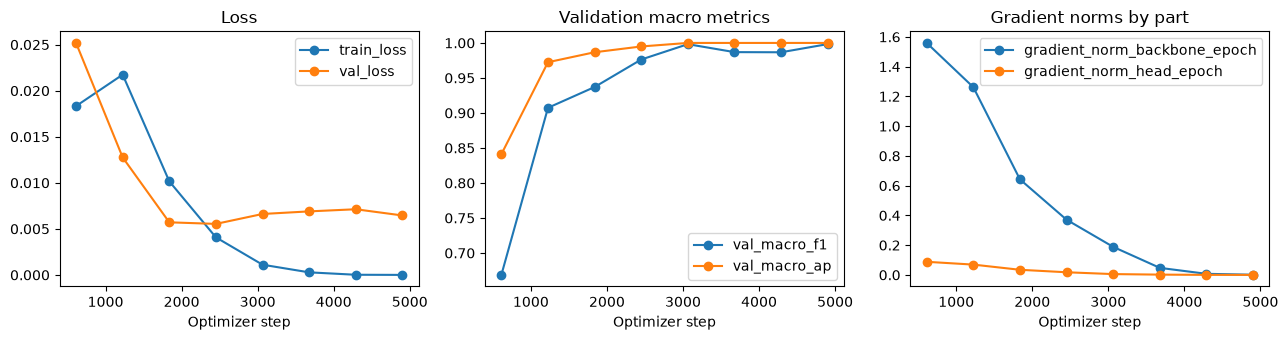

Saved curves: /Users/allakovalcuk/AI301/deep-learning-assignment2/experiments/exp3/results/efficientnetv2s_fold0_seed42/curves.png
Saved gradient flow: /Users/allakovalcuk/AI301/deep-learning-assignment2/experiments/exp3/results/efficientnetv2s_fold0_seed42/gradient_flow.png


In [7]:
if RUN_TRAINING:
    import csv
    import matplotlib.pyplot as plt

    with (Path(logger.log_dir) / 'metrics.csv').open(newline='') as file:
        history = list(csv.DictReader(file))
    figure, axes = plt.subplots(1, 3, figsize=(13, 3.5))
    for axis, names, title in zip(
        axes,
        (('train_loss', 'val_loss'), ('val_macro_f1', 'val_macro_ap'), ('gradient_norm_backbone_epoch', 'gradient_norm_head_epoch')),
        ('Loss', 'Validation macro metrics', 'Gradient norms by part'),
    ):
        for name in names:
            points = [(int(row['step']), float(row[name])) for row in history if row.get(name) not in (None, '')]
            if points:
                axis.plot(*zip(*points), marker='o', label=name)
        axis.set(title=title, xlabel='Optimizer step')
        if axis.lines:
            axis.legend()
    figure.tight_layout()
    curves_path = run_dir / 'curves.png'
    figure.savefig(curves_path, dpi=140)
    plt.show()
    print('Saved curves:', curves_path)
    with record_failures(run_dir, failure_configuration, 'gradient_flow', backup_failure):
        gradient_flow_path = plot_gradient_flow(run_dir / 'diagnostics' / 'layer_gradients.csv', run_dir / 'gradient_flow.png')
    print('Saved gradient flow:', gradient_flow_path)
    if drive_backup is not None:
        drive_backup.save_results([curves_path, gradient_flow_path])
else:
    print('No training curves to plot.')

## Evaluate the selected checkpoint, not the smoke test

After a complete run, reload the best checkpoint and predict all 2,452 fold-0 images in order. Report macro and per-label F1 at the fixed 0.25 threshold, average precision (which does not use the threshold), and F1 at 0.5 for context. A smoke test or stopped timing probe has no reportable score.

In [8]:
COMPLETE_RUN = RUN_TRAINING and not SMOKE_TEST and not PROFILE_ONLY and not budget_exceeded if RUN_TRAINING else False
with record_failures(run_dir, failure_configuration, 'evaluation', backup_failure):
    if COMPLETE_RUN:
        checkpoint_path = Path(checkpoint.best_model_path)
        if not checkpoint_path.is_file():
            raise FileNotFoundError(f'Missing full checkpoint: {checkpoint_path}')
        best_module = FineTuneClassifier.load_from_checkpoint(
            checkpoint_path, network=network, backbone_lr=BACKBONE_LR,
            head_lr=HEAD_LR, weight_decay=WEIGHT_DECAY, threshold=THRESHOLD,
        )
        prediction_started = time.perf_counter()
        predicted_ids, validation_probabilities = predict_probabilities(best_module, validation_loader, DEVICE)
        prediction_seconds = time.perf_counter() - prediction_started
        if predicted_ids != [row['image_id'] for row in validation_rows]:
            raise ValueError('Validation loader changed image order.')
        metrics = score_probabilities(validation_targets, validation_probabilities, THRESHOLD)
        diagnostic_metrics = score_probabilities(validation_targets, validation_probabilities, 0.5)
        print('Fold-0 metrics:', metrics)
        print('F1 at 0.5:', {'macro_f1': diagnostic_metrics['macro_f1'], 'per_label_f1': diagnostic_metrics['per_label_f1']})
    else:
        print('Full-fold evaluation skipped; smoke and timing-gate scores are not results.')

Fold-0 metrics: {'threshold': 0.25, 'macro_f1': 0.9983149573233134, 'per_label_f1': {'Cat': 0.9970501474926253, 'Dog': 0.9945246391239423, 'Moris': 1.0, 'Motya': 1.0, 'Biatrix': 1.0}, 'macro_ap': 0.9999812493994795, 'per_label_ap': {'Cat': 0.9999883920273361, 'Dog': 0.9999178549700615, 'Moris': 0.9999999999999999, 'Motya': 1.0, 'Biatrix': 1.0}}
F1 at 0.5: {'macro_f1': 0.9983153465821907, 'per_label_f1': {'Cat': 0.9965568125922283, 'Dog': 0.9950199203187251, 'Moris': 1.0, 'Motya': 1.0, 'Biatrix': 1.0}}


## Inspect where the model looks

One GradCAM overlay for the first positive validation image of each label, chosen by fold order before looking at predictions. The target is the last MBConv stage (`blocks[-1]`), the final spatial feature map before the 1×1 head convolution. These are illustrations, not evidence that the model learned the right cue.

In [9]:
gradcam_paths = []
with record_failures(run_dir, failure_configuration, 'gradcam', backup_failure):
    if BUILD_GRADCAM and COMPLETE_RUN:
        import matplotlib.pyplot as plt
        from stage2.gradcam import gradcam_map

        output_dir = run_dir / 'gradcam'
        output_dir.mkdir(parents=True, exist_ok=True)
        best_module.to(DEVICE).eval()
        mean = torch.tensor(preprocessing['mean'])[:, None, None]
        std = torch.tensor(preprocessing['std'])[:, None, None]
        for label in LABEL_COLUMNS:
            index = next(i for i, row in enumerate(validation_rows) if row[label] == '1')
            image_id, normalized_image, _ = validation_data[index]
            heatmap = gradcam_map(best_module, normalized_image.unsqueeze(0).to(DEVICE), best_module.network.blocks[-1], LABEL_COLUMNS.index(label)).cpu()
            display_image = (normalized_image * std + mean).clamp(0, 1).permute(1, 2, 0)
            figure, axis = plt.subplots(figsize=(5, 5))
            axis.imshow(display_image)
            axis.imshow(heatmap, cmap='magma', alpha=0.45, vmin=0, vmax=1)
            axis.set(title=f'{label}: {image_id}', xticks=[], yticks=[])
            path = output_dir / f'{label.lower()}_{image_id}.png'
            if path.exists():
                plt.close(figure)
                raise FileExistsError(f'Refusing to overwrite {path}')
            figure.savefig(path, dpi=140, bbox_inches='tight')
            plt.close(figure)
            gradcam_paths.append(path)
            print('Saved GradCAM:', path)
        if drive_backup is not None:
            drive_backup.save_results(gradcam_paths)
    else:
        print('GradCAM skipped.')

Saved GradCAM: /Users/allakovalcuk/AI301/deep-learning-assignment2/experiments/exp3/results/efficientnetv2s_fold0_seed42/gradcam/cat_116d851cb24f39d28f719a743d10df086eb2c793.png
Saved GradCAM: /Users/allakovalcuk/AI301/deep-learning-assignment2/experiments/exp3/results/efficientnetv2s_fold0_seed42/gradcam/dog_e6aea26b070dfe40f6a6121538f00cab344dc03a.png
Saved GradCAM: /Users/allakovalcuk/AI301/deep-learning-assignment2/experiments/exp3/results/efficientnetv2s_fold0_seed42/gradcam/moris_055cb6e1fe1eb7fc077bd98717851ae53de3113c.png
Saved GradCAM: /Users/allakovalcuk/AI301/deep-learning-assignment2/experiments/exp3/results/efficientnetv2s_fold0_seed42/gradcam/motya_cfbc890562e329131f546b43be873f41a06ad195.png
Saved GradCAM: /Users/allakovalcuk/AI301/deep-learning-assignment2/experiments/exp3/results/efficientnetv2s_fold0_seed42/gradcam/biatrix_14ababeb09beeaf8dd430e851e671475ab15fc46.png


## Save the run record and fold-0 probabilities

The JSON follows the Exp1 record layout, so `08_ensemble.ipynb` can read it. Selected checkpoints for sharing go to `experiments/exp3/checkpoints/<run-id>_best.ckpt` (Git LFS); the working checkpoint stays Git-ignored in the run directory. Record the public score in the README after a manual Kaggle upload.

In [10]:
git_commit = subprocess.run(['git', 'rev-parse', 'HEAD'], cwd=ROOT, capture_output=True, text=True, check=True).stdout.strip() if (ROOT / '.git').exists() else None
source_files = (ROOT / 'notebooks' / '09_efficientnet.ipynb', ROOT / 'stage2' / 'experiment.py', ROOT / 'stage2' / 'train.py', ROOT / 'stage2' / 'finetune.py', ROOT / 'stage2' / 'batchnorm.py', ROOT / 'stage2' / 'run_records.py', ROOT / 'stage2' / 'diagnostics.py', ROOT / 'stage2' / 'gradcam.py')
source_sha256 = {str(path.relative_to(ROOT)): file_sha256(path) for path in source_files}
with record_failures(run_dir, failure_configuration, 'results', backup_failure):
    if COMPLETE_RUN:
        probability_path = run_dir / f'{RUN_ID}_val.csv'
        record_path = run_dir / f'{RUN_ID}.json'
        for path in (probability_path, record_path):
            if path.exists():
                raise FileExistsError(f'Refusing to overwrite {path}')
        record = {**run_configuration, 'run_id': RUN_ID, 'experiment': '03_efficientnetv2_s', 'status': 'completed',
                  'git_commit': git_commit, 'source_sha256': source_sha256,
                  'training': {**run_configuration['training'], 'epochs_completed': trainer.fit_loop.epoch_progress.current.completed},
                  'hardware': diagnostics.memory,
                  'trainable_parameters': sum(p.numel() for p in network.parameters() if p.requires_grad),
                  'metrics': {**metrics, 'macro_f1_at_0_5': diagnostic_metrics['macro_f1'], 'per_label_f1_at_0_5': diagnostic_metrics['per_label_f1']},
                  'timings': {'head_warmup_seconds': head_seconds, 'training_and_validation_seconds': training_seconds, 'epoch_seconds': checkpoint.epoch_seconds,
                              'first_epoch_projected_seconds': checkpoint.projected_seconds, 'best_checkpoint_prediction_seconds': prediction_seconds},
                  'artifacts': {'validation_probabilities_csv': str(probability_path.relative_to(ROOT)), 'best_checkpoint_local': str(checkpoint_path.relative_to(ROOT)),
                                'best_checkpoint_sha256': file_sha256(checkpoint_path), 'curves_csv': str((Path(logger.log_dir) / 'metrics.csv').relative_to(ROOT)),
                                'layer_gradients_csv': str((run_dir / 'diagnostics' / 'layer_gradients.csv').relative_to(ROOT)), 'gradient_flow_png': str(gradient_flow_path.relative_to(ROOT)),
                                'memory_json': str((run_dir / 'diagnostics' / 'memory.json').relative_to(ROOT)), 'gradcam_images': [str(path.relative_to(ROOT)) for path in gradcam_paths],
                                'drive_backup_dir': str(drive_backup.drive_dir) if drive_backup is not None else None},
                  'versions': {'python': platform.python_version(), 'torch': torch.__version__, 'timm': timm.__version__, 'lightning': L.__version__},
                  'telemetry': {'wandb_enabled': USE_WANDB, 'wandb_mode': WANDB_MODE if USE_WANDB else None, 'wandb_project': WANDB_PROJECT if USE_WANDB else None, 'wandb_run_id': wandb_logger.version if wandb_logger is not None else None, 'model_upload': False},
                  'public_leaderboard_score': None, 'error': None}
        write_probabilities(probability_path, predicted_ids, validation_probabilities, VALIDATION_FOLD)
        write_run_record(record_path, record)
        print('Saved:', record_path, probability_path, sep='\n')
        if drive_backup is not None:
            drive_backup.save_results([record_path, probability_path])
    else:
        print('No full-run artifacts written.')

Saved:
/Users/allakovalcuk/AI301/deep-learning-assignment2/experiments/exp3/results/efficientnetv2s_fold0_seed42/efficientnetv2s_fold0_seed42.json
/Users/allakovalcuk/AI301/deep-learning-assignment2/experiments/exp3/results/efficientnetv2s_fold0_seed42/efficientnetv2s_fold0_seed42_val.csv


## Predict the test images, if we want to ensemble

With `STAGE2_BUILD_TEST_PREDICTIONS=1`, the notebook predicts the 18,673 test images with the selected checkpoint and saves the probabilities next to the run as `<run-id>_test/`, in the same layout `08_ensemble.ipynb` reuses for Exp1 and Exp2. The Kaggle CSV is made in the next cell, from these saved probabilities.

In [11]:
if BUILD_TEST_PREDICTIONS and COMPLETE_RUN:
    with record_failures(run_dir, failure_configuration, 'test_inference', backup_failure):
        test_rows = read_csv(DATA_DIR / 'test.csv', ('image_id',))
        preflight_images(test_rows, DATA_DIR / 'test')
        test_data = ImageDataset(test_rows, DATA_DIR / 'test', IMAGE_SIZE, preprocessing['mean'], preprocessing['std'])
        test_loader = DataLoader(test_data, shuffle=False, **loader_options)
        started = time.perf_counter()
        test_ids, test_probabilities = predict_probabilities(best_module, test_loader, DEVICE)
        test_seconds = time.perf_counter() - started
        if test_ids != [row['image_id'] for row in test_rows]:
            raise ValueError('Test loader changed image order.')
        test_dir = run_dir.parent / f'{RUN_ID}_test'
        write_test_probabilities(test_dir / f'{RUN_ID}_test.csv', test_ids, test_probabilities)
        write_run_record(test_dir / f'{RUN_ID}_test.json', {
            'run_id': f'{RUN_ID}_test', 'experiment': record['experiment'], 'status': 'test_predicted', 'source_run_id': RUN_ID,
            'source_checkpoint_sha256': record['artifacts']['best_checkpoint_sha256'], 'test_images': len(test_ids),
            'transform': record['data']['transform'] + '; no test-time augmentation', 'git_commit': git_commit, 'source_sha256': source_sha256,
            'device': str(DEVICE), 'prediction_seconds': test_seconds, 'versions': record['versions'],
        })
        print(f'Saved test probabilities in {test_seconds / 60:.1f} min:', test_dir)
        print('Positives at 0.25:', {label: int((test_probabilities[:, i] >= THRESHOLD).sum()) for i, label in enumerate(LABEL_COLUMNS)})
        if drive_backup is not None:
            drive_backup.save_results(sorted(test_dir.iterdir()))
else:
    print('No test predictions built or uploaded.')

Saved test probabilities in 6.6 min: /Users/allakovalcuk/AI301/deep-learning-assignment2/experiments/exp3/results/efficientnetv2s_fold0_seed42_test
Positives at 0.25: {'Cat': 7809, 'Dog': 7659, 'Moris': 161, 'Motya': 129, 'Biatrix': 181}


## Make the Kaggle submission file

With `BUILD_SUBMISSION = True` in the first code cell, this cell turns the saved test probabilities into the 0/1 CSV the competition scores. It reads `<run-id>_test/` from disk, so it works in a fresh session too: run the first code cell and the data cell, then this one, with `RUN_TRAINING = False` if you do not want to train again. It checks that the probabilities came from the run's selected checkpoint, applies the fixed 0.25 threshold, and writes the rows in `sample_submission.csv` order. It refuses to overwrite an existing file. Nothing is uploaded: upload the CSV on Kaggle by hand and note the public score.

In [16]:
if BUILD_SUBMISSION:
    import json  # Imported here so the cell works in a session that started before it was added.
    from stage2.ensemble import read_probabilities

    test_dir = ROOT / 'experiments' / 'exp3' / 'results' / f'{RUN_ID}_test'
    run_record = json.loads((ROOT / 'experiments' / 'exp3' / 'results' / RUN_ID / f'{RUN_ID}.json').read_text())
    test_record = json.loads((test_dir / f'{RUN_ID}_test.json').read_text())
    if run_record['status'] != 'completed' or test_record['source_checkpoint_sha256'] != run_record['artifacts']['best_checkpoint_sha256']:
        raise ValueError('The saved test probabilities do not come from this completed run\'s selected checkpoint.')
    submission_ids = [row['image_id'] for row in read_csv(DATA_DIR / 'test.csv', ('image_id',))]
    saved_probabilities = read_probabilities(test_dir / f'{RUN_ID}_test.csv', submission_ids)
    submission_path = ROOT / 'submissions' / f'exp3_{RUN_ID}_{round(THRESHOLD * 100):03d}.csv'
    write_submission(submission_path, form_submission(DATA_DIR / 'sample_submission.csv', submission_ids, saved_probabilities, THRESHOLD))
    submission_rows = read_csv(submission_path, ('image_id', *LABEL_COLUMNS))
    assert len(submission_rows) == len(submission_ids) and all(row[label] in ('0', '1') for row in submission_rows for label in LABEL_COLUMNS)
    print('CSV ready for manual review:', submission_path.relative_to(ROOT))
    print(f'{len(submission_rows)} rows; positives at {THRESHOLD}:', {label: sum(int(row[label]) for row in submission_rows) for label in LABEL_COLUMNS})
else:
    print('No submission CSV built or uploaded.')

FileExistsError: Refusing to overwrite /Users/allakovalcuk/AI301/deep-learning-assignment2/submissions/exp3_efficientnetv2s_fold0_seed42_025.csv

## Results and conclusions

| Model | Fold-0 macro F1 at 0.25 | Public leaderboard |
|---|---:|---:|
| Exp1: ConvNeXt-base, standard fine-tuning (88M parameters) | 0.97518 | 0.97003 |
| Exp2: ConvNeXt + residual spatial block | 0.97401 | 0.96043 |
| **Exp3: EfficientNetV2-S** (20M parameters, this notebook) | **0.99831** | 0.97015 |
| Mean of Exp1 and Exp2 | 0.97528 | 0.96824 |

**1. On the leaderboard Exp3 only ties Exp1.** 0.97015 against 0.97003 is +0.00012. At the test set's counts one named-pet photo is worth roughly 0.0007 macro F1, so this is well under one photo and we do not read it as a win.

**2. The large fold-0 gain did not carry over.** Exp3 scored 0.023 above Exp1 on fold 0, but that is exactly two named-pet photos (a Motya miss and a Biatrix false alarm that Exp1 makes), because each pet has only 8–10 validation photos and one photo moves macro F1 by about 0.012. The distance between fold 0 and the leaderboard is 0.028 for Exp3 against 0.005 for Exp1. The likely reasons, not separately tested, are selection on fold 0 and a harder test set. All three fine-tuned runs drive their training loss to about zero, but only Exp3's validation loss rises afterwards (0.0055 at epoch 4 to 0.0071 at epoch 7) and it ends about twice as high as the ConvNeXt runs' (about 0.003). That points to overconfident wrong predictions, not a drop in accuracy. Likely causes, not tested here: learning rates ten times higher than the ConvNeXt runs, almost no regularization beyond a random flip, and only 35–45 training photos per named pet. Macro F1 jumped between 0.987 and 0.998 across epochs, which is one Biatrix photo. The fold-0 score cannot rank two models that differ by one or two photos.

**3. The same quality at lower cost.** Exp3 has about a quarter of Exp1's parameters and ran at 13.7 minutes per epoch on the Mac's GPU, against about 42 minutes per epoch for Exp2. The full run took 142 minutes: 32 minutes for the head warm-up and 109 for fine-tuning. Peak GPU memory was about 5 GB.

**4. A different family makes different mistakes.** On the test set Exp3 and Exp1 disagree in 219 label cells, 3.3 times as many as Exp1 and Exp2 (66). Their public scores are almost equal, so averaging them is our next experiment (`10_ensemble_exp1_exp3.ipynb`). Exp3 is also more decisive about named pets on test. Of its 161 Moris predictions, 153 have probability 0.75 or higher and only 8 lie between 0.25 and 0.75.

**5. What went wrong on the way.** The first head warm-up used three epochs and stopped at macro F1 0.774, with the rare labels still improving. We raised it to eight epochs (0.910). Phase 2 first started with the network in eval mode, which we fixed. Several smoke-run and notebook mistakes came from changing a flag without rerunning the setup cells, so the notebook now fails with a clear message in that situation.

**Limits.** One seed and one fold. The learning rates (`1e-4` backbone, `1e-3` head), the flip-only augmentation and the frozen BatchNorm statistics were chosen once and not tuned, and we ran no ablation of them. A different seed could change the named-pet result on fold 0 by a photo or two.